# Probability Ensemble

Averages compatible OOF and test probability artifacts from multiple model runs, then selects the decision threshold from OOF F1.

## Overview

- Loads multiple `.npz` probability artifacts with matching train/test dimensions.
- Averages OOF and test probabilities for model stability.
- Tunes the ensemble threshold on OOF labels only.
- Writes `bertweet_two_seed_submission.csv` and `artifacts/bertweet_ensemble_predictions.npz`.
- Includes diagnostics for component agreement and ensemble threshold behavior.

Source script: `ensemble_probabilities.py`


## Environment Setup

### Required Packages

Install the project dependencies from the repository root:

```bash
python3 -m venv .venv
.venv/bin/pip install -r requirements.txt
```

### Notebook Path

Run notebooks from the repository root when possible. If you open a notebook from `notebooks/`, the root-detection cell resolves the parent project directory automatically.

### Hardware Requirements

- CPU is sufficient for sparse, ensemble, and blend notebooks.
- A CUDA or Apple Silicon MPS GPU is recommended for BERTweet fine-tuning.
- 8 GB RAM is the minimum; 16 GB or more is recommended.


## What This Notebook Does

- Builds the two-seed BERTweet probability ensemble.
- Requires compatible OOF/test probability arrays from upstream runs.
- Produces ensemble artifacts for the final blend.


## Run Setup

Run notebooks from the repository root when possible. If you open a notebook from the `notebooks/` folder, the project-root detection cell below will still resolve the parent project directory.


In [4]:
# Optional setup for a fresh local runtime. Uncomment if dependencies are missing.
# %pip install -r requirements.txt
# %pip install -r ../requirements.txt

# Result summary: output for notebook cell 4
import importlib.util as _importlib_util
import pandas as _setup_pd
_setup_packages = ["pandas", "numpy", "scikit-learn", "matplotlib", "seaborn"]
_setup_pd.DataFrame(
    {
        "package": _setup_packages,
        "available": [_importlib_util.find_spec(name.replace("scikit-learn", "sklearn")) is not None for name in _setup_packages],
    }
).set_index("package")


,available
package,
pandas,True
numpy,True
scikit-learn,True
matplotlib,True
seaborn,True


## Imports And Configuration


In [5]:
from __future__ import annotations

import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score


try:
    ROOT = Path(__file__).resolve().parent
except NameError:
    ROOT = Path.cwd()
    if not (ROOT / "data/train.csv").exists() and (ROOT.parent / "data/train.csv").exists():
        ROOT = ROOT.parent

# Result summary: output for notebook cell 6
import inspect

pd.Series(
    {
        "project_root": str(ROOT),
        "train_file_exists": (ROOT / "data/train.csv").exists(),
        "test_file_exists": (ROOT / "data/test.csv").exists(),
        "ensemble_artifact_exists": (ROOT / "artifacts/bertweet_ensemble_predictions.npz").exists(),
    },
    name="runtime",
)


project_root                /Users/aftabhossain/Downloads/Competition
train_file_exists                                                True
test_file_exists                                                 True
ensemble_artifact_exists                                         True
Name: runtime, dtype: object

## Visualization Setup

The following cells use a shared plotting theme so exploratory charts, validation curves, and artifact diagnostics read consistently across the notebook series.


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "savefig.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "axes.edgecolor": "#d1d5db",
        "grid.color": "#e5e7eb",
        "legend.frameon": False,
    }
)

CLASS_COLORS = {
    "Not disaster": "#2563eb",
    "Disaster": "#dc2626",
    "Train": "#2563eb",
    "Test": "#059669",
}



In [7]:
def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument(
        "--inputs",
        type=Path,
        nargs="+",
        default=[
            ROOT / "artifacts/bertweet_full/predictions.npz",
            ROOT / "artifacts/bertweet_seed99173/predictions.npz",
        ],
        help="Completed *.npz artifacts with OOF and test scores.",
    )
    parser.add_argument("--train-path", type=Path, default=ROOT / "data/train.csv")
    parser.add_argument("--test-path", type=Path, default=ROOT / "data/test.csv")
    parser.add_argument("--output", type=Path, default=ROOT / "bertweet_two_seed_submission.csv")
    parser.add_argument(
        "--artifact-output", type=Path, default=ROOT / "artifacts/bertweet_ensemble_predictions.npz"
    )
    parser.add_argument(
        "--metadata", type=Path, default=ROOT / "artifacts/bertweet_ensemble_metadata.json"
    )
    return parser.parse_args(args=[])


# Result summary: show the configured input artifacts and their availability.
args = parse_args()
pd.DataFrame(
    {
        "input_artifact": [str(path) for path in args.inputs],
        "exists": [path.exists() for path in args.inputs],
    }
)


,input_artifact,exists
0,/Users/aftabhossain/Downloads/Competition/arti...,True
1,/Users/aftabhossain/Downloads/Competition/arti...,True


## Artifact Loading


In [8]:
def load(path: Path) -> tuple[np.ndarray, np.ndarray]:
    values = np.load(path)
    if "oof_probability" not in values.files or "test_probability" not in values.files:
        raise ValueError(f"{path} is missing required probability arrays")
    oof = np.asarray(values["oof_probability"], dtype=float)
    test = np.asarray(values["test_probability"], dtype=float)
    if np.isnan(oof).any() or np.isnan(test).any():
        raise ValueError(f"{path} contains incomplete values")
    return oof, test

# Result summary: output for notebook cell 11
_ensemble_demo_path = next((path for path in parse_args().inputs if path.exists()), None)
if _ensemble_demo_path is None:
    pd.DataFrame({"artifact_status": ["No compatible probability artifact is available."]})
else:
    _ensemble_demo_oof, _ensemble_demo_test = load(_ensemble_demo_path)
    pd.DataFrame(
        {
            "artifact": [str(_ensemble_demo_path)],
            "oof_rows": [len(_ensemble_demo_oof)],
            "test_rows": [len(_ensemble_demo_test)],
            "oof_min": [_ensemble_demo_oof.min()],
            "oof_max": [_ensemble_demo_oof.max()],
        }
    )


## Threshold Selection


In [9]:
def best_f1(labels: np.ndarray, probability: np.ndarray) -> tuple[float, float]:
    thresholds = np.arange(0.20, 0.801, 0.0025)
    scores = [f1_score(labels, probability >= threshold) for threshold in thresholds]
    index = int(np.argmax(scores))
    return float(scores[index]), float(thresholds[index])

# Result summary: output for notebook cell 13
_ensemble_threshold_labels = np.array([0, 0, 1, 1])
_ensemble_threshold_probabilities = np.array([0.10, 0.35, 0.60, 0.90])
_ensemble_score, _ensemble_threshold = best_f1(_ensemble_threshold_labels, _ensemble_threshold_probabilities)
pd.DataFrame({"best_threshold": [_ensemble_threshold], "f1": [_ensemble_score]})


,best_threshold,f1
0,0.35,1.0


## Pipeline Entry Point


In [10]:
def main() -> None:
    args = parse_args()
    train = pd.read_csv(args.train_path)
    test = pd.read_csv(args.test_path)
    labels = train.target.astype(int).to_numpy()
    arrays = [load(path) for path in args.inputs]
    if any(len(oof) != len(labels) or len(prediction) != len(test) for oof, prediction in arrays):
        raise ValueError("Artifact row counts do not match competition data.")
    oof_probability = np.mean([oof for oof, _ in arrays], axis=0)
    test_probability = np.mean([prediction for _, prediction in arrays], axis=0)
    score, threshold = best_f1(labels, oof_probability)
    predictions = (test_probability >= threshold).astype(int)
    args.output.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"id": test.id, "target": predictions}).to_csv(args.output, index=False)
    args.artifact_output.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(args.artifact_output, oof_probability=oof_probability, test_probability=test_probability)
    metadata = {
        "inputs": [str(path) for path in args.inputs],
        "data_provenance": "Only OOF predictions from models trained on data/train.csv labels.",
        "oof_f1": score,
        "oof_auc": float(roc_auc_score(labels, oof_probability)),
        "threshold": threshold,
        "test_positive_count": int(predictions.sum()),
        "test_positive_rate": float(predictions.mean()),
        "output": str(args.output),
    }
    args.metadata.write_text(json.dumps(metadata, indent=2))
    print(
        f"Averaged {len(arrays)} artifacts: OOF F1={score:.5f} AUC={metadata['oof_auc']:.5f} "
        f"threshold={threshold:.3f}, positives={predictions.sum()}/{len(predictions)}",
        flush=True,
    )

# Result summary: output for notebook cell 15
pd.DataFrame(
    {
        "pipeline_stage": ["load", "average", "threshold", "write"],
        "result": ["compatible OOF and test arrays", "mean probability per row", "OOF-selected F1 threshold", "submission, NPZ artifact, and metadata"],
    }
)


,pipeline_stage,result
0,load,compatible OOF and test arrays
1,average,mean probability per row
2,threshold,OOF-selected F1 threshold
3,write,"submission, NPZ artifact, and metadata"


## Execute

Review the defaults in `parse_args()` first. Uncomment `main()` when you want the notebook to run the full pipeline and write artifacts.


In [11]:
main()



Averaged 2 artifacts: OOF F1=0.81716 AUC=0.89466 threshold=0.545, positives=1258/3263


## Ensemble Visual Diagnostics

Run this after generating compatible probability artifacts. The charts compare component predictions, their agreement, and the ensemble threshold curve.


Ensemble OOF F1=0.81716 at threshold=0.545


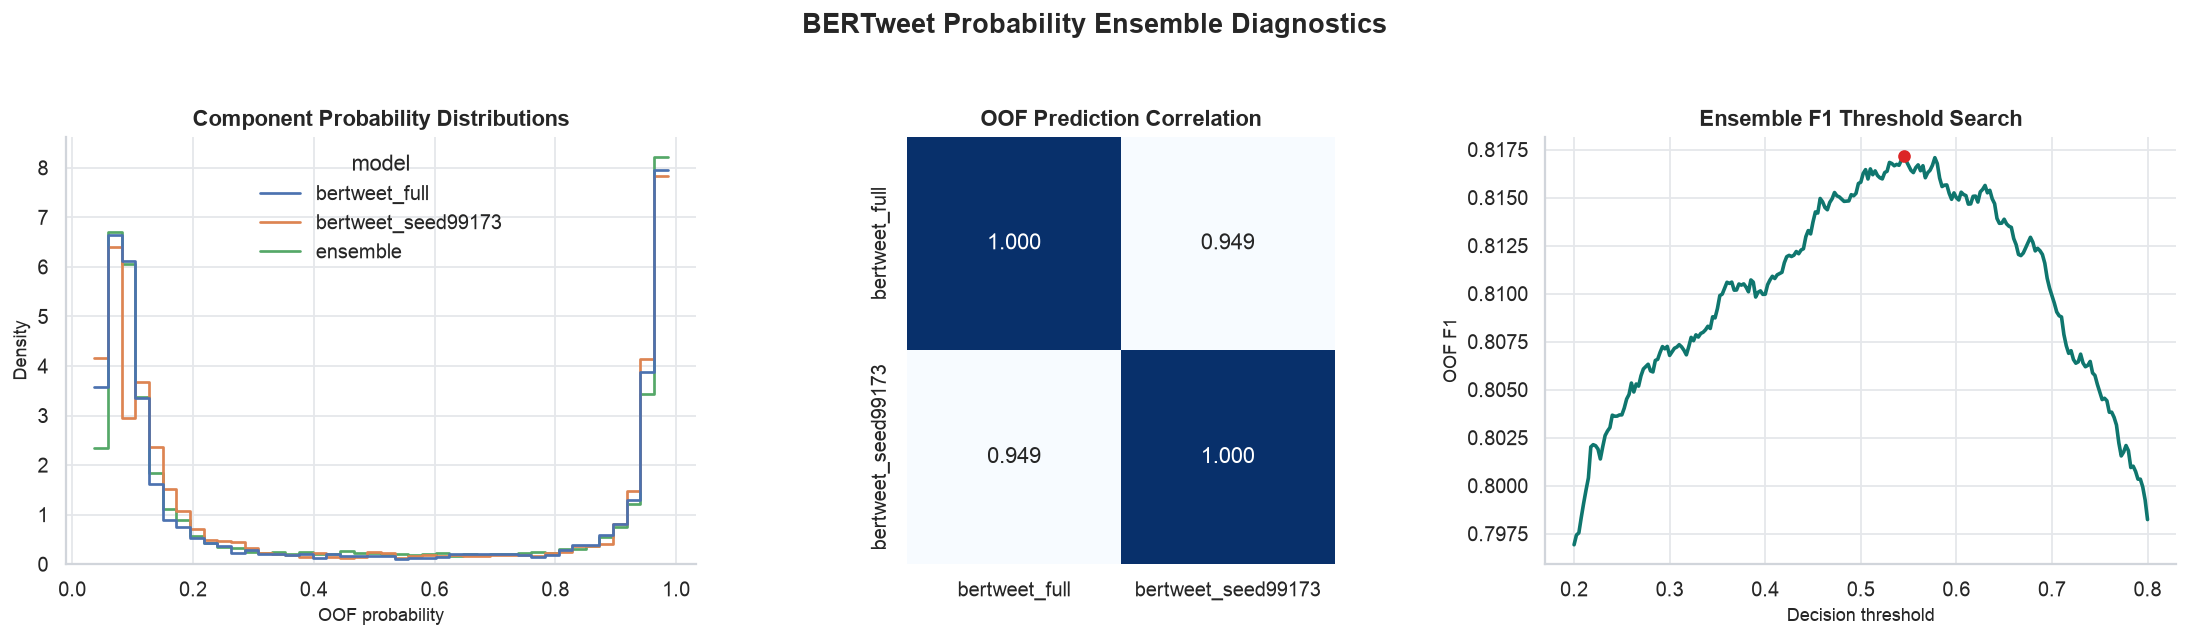

In [12]:
train_labels = pd.read_csv(ROOT / "data/train.csv")["target"].astype(int).to_numpy()
metadata_path = ROOT / "artifacts/bertweet_ensemble_metadata.json"
ensemble_path = ROOT / "artifacts/bertweet_ensemble_predictions.npz"
default_inputs = [
    ROOT / "artifacts/bertweet_full/predictions.npz",
    ROOT / "artifacts/bertweet_seed99173/predictions.npz",
]

if metadata_path.exists():
    metadata = json.loads(metadata_path.read_text())
    input_paths = [Path(path) for path in metadata.get("inputs", [])]
else:
    metadata = {}
    input_paths = default_inputs

input_paths = [path if path.is_absolute() else ROOT / path for path in input_paths]
available_inputs = [path for path in input_paths if path.exists()]
if not available_inputs:
    available_inputs = [path for path in default_inputs if path.exists()]

if not ensemble_path.exists() or not available_inputs:
    print("No complete ensemble artifact set found yet. Run the ensemble pipeline first, then rerun this diagnostics cell.")
else:
    component_series = {}
    for path in available_inputs:
        values = np.load(path)["oof_probability"]
        if len(values) == len(train_labels):
            component_series[path.parent.name] = values

    ensemble_values = np.load(ensemble_path)["oof_probability"]
    threshold = float(metadata.get("threshold", best_f1(train_labels, ensemble_values)[1]))
    score = float(metadata.get("oof_f1", best_f1(train_labels, ensemble_values)[0]))
    threshold_grid = np.arange(0.20, 0.801, 0.0025)
    f1_curve = [f1_score(train_labels, ensemble_values >= value) for value in threshold_grid]

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))

    component_frame = pd.concat(
        [
            pd.DataFrame({"probability": values, "model": name})
            for name, values in component_series.items()
        ]
        + [pd.DataFrame({"probability": ensemble_values, "model": "ensemble"})],
        ignore_index=True,
    )
    sns.histplot(
        data=component_frame,
        x="probability",
        hue="model",
        bins=42,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=axes[0],
    )
    axes[0].set_title("Component Probability Distributions")
    axes[0].set_xlabel("OOF probability")
    axes[0].set_ylabel("Density")

    correlation_frame = pd.DataFrame(component_series)
    if len(correlation_frame.columns) >= 2:
        sns.heatmap(
            correlation_frame.corr(),
            annot=True,
            fmt=".3f",
            cmap="Blues",
            square=True,
            cbar=False,
            ax=axes[1],
        )
        axes[1].set_title("OOF Prediction Correlation")
    else:
        axes[1].text(0.5, 0.5, "Need at least two components", ha="center", va="center")
        axes[1].set_axis_off()

    axes[2].plot(threshold_grid, f1_curve, color="#0f766e", linewidth=2)
    axes[2].scatter([threshold], [score], color="#dc2626", zorder=3)
    axes[2].set_title("Ensemble F1 Threshold Search")
    axes[2].set_xlabel("Decision threshold")
    axes[2].set_ylabel("OOF F1")

    fig.suptitle("BERTweet Probability Ensemble Diagnostics", fontsize=15, fontweight="bold", y=1.04)
    plt.tight_layout()
    print(f"Ensemble OOF F1={score:.5f} at threshold={threshold:.3f}")

